# Detected walls vs. tag locations

Visualizes the held-out predictions of `roomsweeps_wall_distance_multitag.py` (leave one experiment out) on the
top-down room scan.

That script predicts, for a cluster of tags, the distance **d** from the cluster centroid **C** to its closest wall.
The model gives only a distance, not a direction, so each prediction is drawn as a **detected wall point** on the
true closest wall's normal:

$$\text{detected point} = C - \frac{\hat d}{100}\,\mathbf{n} \qquad\qquad \text{true foot} = C - \frac{d}{100}\,\mathbf{n}$$

where **n** is that wall's unit normal pointing into the room (`find_walls()` in `roomsweeps_wall_distance.py`).
A perfect prediction lands on the real wall (the dark wall points of the scan). Over-predicting puts the point
behind the wall and under-predicting puts it inside the room. The wall lines fitted by `find_walls()` (the targets'
reference) are not drawn.

- The grey background is the merged room scan: light points are floor, dark points are walls and furniture (as in
  `roomsweeps_processing.ipynb`).
- The detected wall of an experiment is the `find_walls()` wall shifted by the median signed error of that experiment's
  clusters (dashed line).

Inputs, from `roomsweeps_wall_distance_multitag_out/`: `predictions_<RUN>.csv` (one row per held-out cluster) and
`folds_<RUN>.csv` (per-experiment MAE).

In [25]:
RUN = "n7_span150cm_relpos"                      # suffix of the *_<RUN>.csv files in roomsweeps_wall_distance_multitag_out/
MODELS = None                             # models to plot, each in its own figures; None = all, e.g. ["SVR", "Transformer (hierarchical)"]
EXP = 2                                   # experiment drawn large at the end
SHOW_LABELS = True                        # write the floor label next to each tag

In [26]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patheffects import withStroke
import open3d as o3d

from roomsweeps_wall_distance import MESH_PATH, PART_COLORS, all_positions, find_walls, markers

OUT = Path.cwd() / "roomsweeps_wall_distance_multitag_out"
pred = pd.read_csv(OUT / f"predictions_{RUN}.csv")
folds = pd.read_csv(OUT / f"folds_{RUN}.csv").set_index("exp")
available = [c[len("pred_"):] for c in pred.columns if c.startswith("pred_") and c != "pred_mean of train"]
models = available if MODELS is None else list(MODELS)
assert set(models) <= set(available), f"unknown models {set(models) - set(available)}; available: {available}"

walls = find_walls()                                     # {"Edge02 wall (beyond col 0)": (point, normal into room, dir)}
wall_key = {name.split(" (", 1)[0]: name for name in walls}   # "Edge02 wall" -> full name
WALL_COLORS = dict(zip(wall_key, PART_COLORS))

positions = all_positions()
print(f"{len(pred)} held-out clusters in {pred.exp.nunique()} experiments; models: {', '.join(models)}")
print("closest wall:", pred.wall.value_counts().to_dict())

11084 held-out clusters in 17 experiments; models: SVR, MLP (DeepSets), ResCNN (frequency fusion), Transformer (hierarchical)
closest wall: {'Row-1 wall': 8556, 'Edge01 wall': 1304, 'Edge02 wall': 1224}


## Geometry

`detections(model)` adds, for every cluster, the true foot on its closest wall (`foot_x, foot_y`), the detected
point (`det_x, det_y`) and the signed error `err_cm` (prediction minus truth; positive means the detection is behind
the wall). `wall_segment(name)` gives the wall line's ends: the wall's tangent, spanned over the floor grid plus a
margin.

`fit_detected_wall(g, name)` fits a line to the detected points of one wall by total least squares (first principal
axis of the point cloud), so its direction and position come from the estimates alone. It returns the line's ends
(2nd–98th percentile of the points along it), its angle to the scan wall (degrees) and its offset (cm, positive =
behind the wall, measured at the cloud's centre).

In [27]:
def wall_normal(name):
    return walls[wall_key[name]][1]


def detections(model):
    d = pred.copy()
    n = np.stack([wall_normal(w) for w in d.wall])
    c = d[["centroid_x", "centroid_y"]].to_numpy()
    foot = c - (d.wall_cm.to_numpy() / 100)[:, None] * n
    det = c - (d[f"pred_{model}"].to_numpy() / 100)[:, None] * n
    d[["foot_x", "foot_y"]], d[["det_x", "det_y"]] = foot, det
    d["err_cm"] = d[f"pred_{model}"] - d.wall_cm
    return d


def wall_segment(name, offset_cm=0.0, margin=0.5):
    """Ends of the wall line, shifted offset_cm away from the room (positive = behind the wall)."""
    point, normal, _ = walls[wall_key[name]]
    u = np.array([-normal[1], normal[0]])
    t = (markers[["x", "y"]].to_numpy() - point) @ u
    p = point - offset_cm / 100 * normal
    return np.array([p + (t.min() - margin) * u, p + (t.max() + margin) * u])


def fit_detected_wall(g, name):
    xy = g[["det_x", "det_y"]].to_numpy()
    c = xy.mean(0)
    u = np.linalg.svd(xy - c, full_matrices=False)[2][0]          # direction of largest spread
    t = (xy - c) @ u
    ends = c + np.percentile(t, [2, 98])[:, None] * u
    point, normal, _ = walls[wall_key[name]]
    tangent = np.array([-normal[1], normal[0]])
    angle = np.degrees(np.arctan2(u @ normal, u @ tangent))
    angle = (angle + 90) % 180 - 90                               # a line has no sign: fold into [-90, 90)
    offset = -100 * (c - point) @ normal
    return ends, angle, offset


det = {m: detections(m) for m in models}

## Room background

Same rendering as `roomsweeps_processing.ipynb`: scan points below `FLOOR_Z` are floor, those in `OBST_Z` are walls
and furniture.

In [28]:
mesh = o3d.io.read_triangle_mesh(str(MESH_PATH))
verts = np.asarray(mesh.vertices)
FLOOR_Z, OBST_Z = 0.15, (0.3, 2.0)
rng = np.random.default_rng(0)
floor = verts[:, 2] < FLOOR_Z
obst = (verts[:, 2] > OBST_Z[0]) & (verts[:, 2] < OBST_Z[1])
floor_idx = rng.choice(np.flatnonzero(floor), min(80_000, floor.sum()), replace=False)
obst_idx = rng.choice(np.flatnonzero(obst), min(40_000, obst.sum()), replace=False)


def draw_room(ax, grid=True):
    ax.scatter(verts[floor_idx, 0], verts[floor_idx, 1], c="#cfcfcf", s=0.3, alpha=0.5, linewidths=0, rasterized=True)
    ax.scatter(verts[obst_idx, 0], verts[obst_idx, 1], c="#555555", s=0.3, alpha=0.35, linewidths=0, rasterized=True)
    if grid:
        ax.scatter(markers.x, markers.y, s=4, c="#9a9a9a", zorder=2)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.grid(True, color="#dddddd", lw=0.5)


def set_room_limits(ax, pad=0.9):
    ends = np.concatenate([wall_segment(w) for w in wall_key])
    ax.set_xlim(ends[:, 0].min() - pad, ends[:, 0].max() + pad)
    ax.set_ylim(ends[:, 1].min() - pad, ends[:, 1].max() + pad)


def draw_tags(ax, exp, color="#2a78d6", size=40):
    pos = positions[str(exp)]
    xy = markers.loc[pos.label, ["x", "y"]].to_numpy()
    ax.scatter(xy[:, 0], xy[:, 1], s=size, color=color, edgecolors="white", linewidths=0.8, zorder=7)
    if SHOW_LABELS:
        for lab, (x, y) in zip(pos.label, xy):
            ax.annotate(str(lab), (x, y), xytext=(3, 3), textcoords="offset points", fontsize=6.5,
                        color="#222222", zorder=8)


def wall_legend(ax, extra=(), loc="upper right"):
    handles = [Line2D([], [], marker="o", ls="", color=WALL_COLORS[w], markersize=6, label=f"detected, {w}")
                for w in wall_key if w in pred.wall.values]
    ax.legend(handles=handles + list(extra), loc=loc, fontsize=8, frameon=True, framealpha=0.9)

## All experiments pooled (one figure per model)

Every held-out cluster's detected wall point, coloured by the wall it was measured to. The tighter the cloud hugs
the wall in the scan, the better the model. The solid line through each cloud is the line fitted to those estimates
(`fit_detected_wall`); the legend gives its angle to the scan wall and its offset (positive = behind the wall). The mean-of-train baseline is left out: it predicts nearly the same distance
for every cluster.

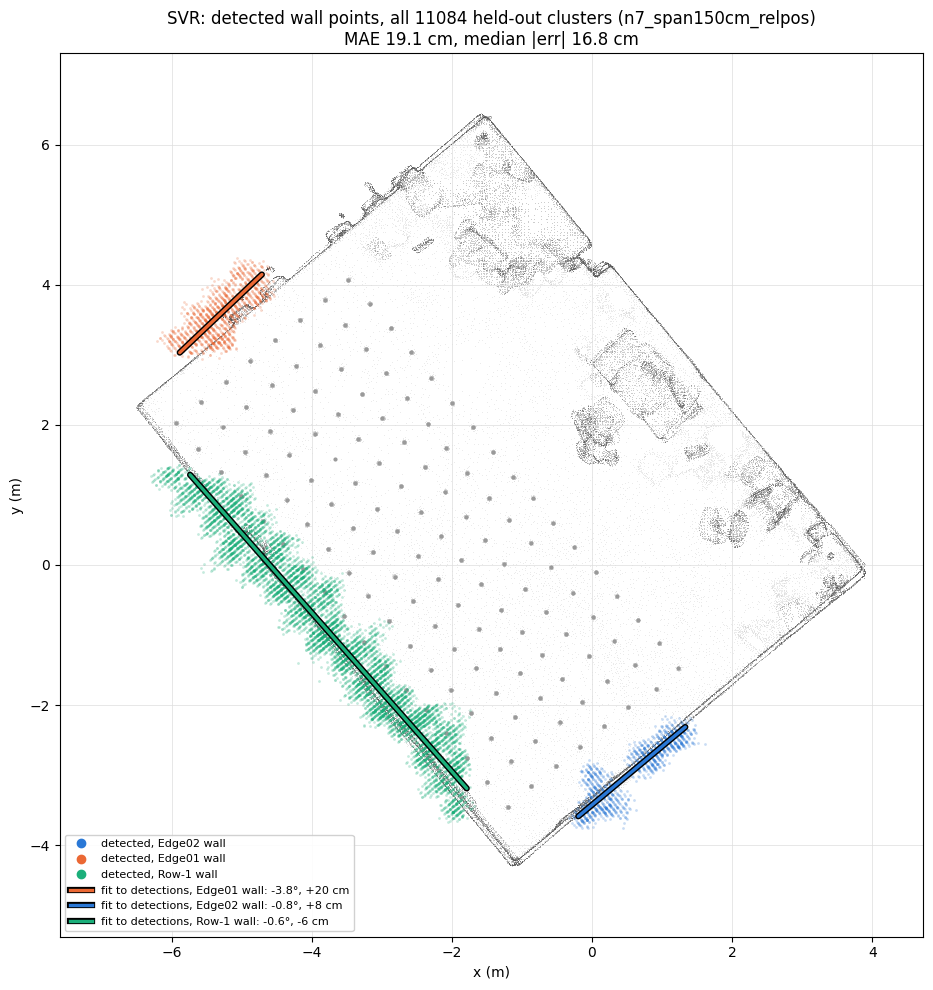

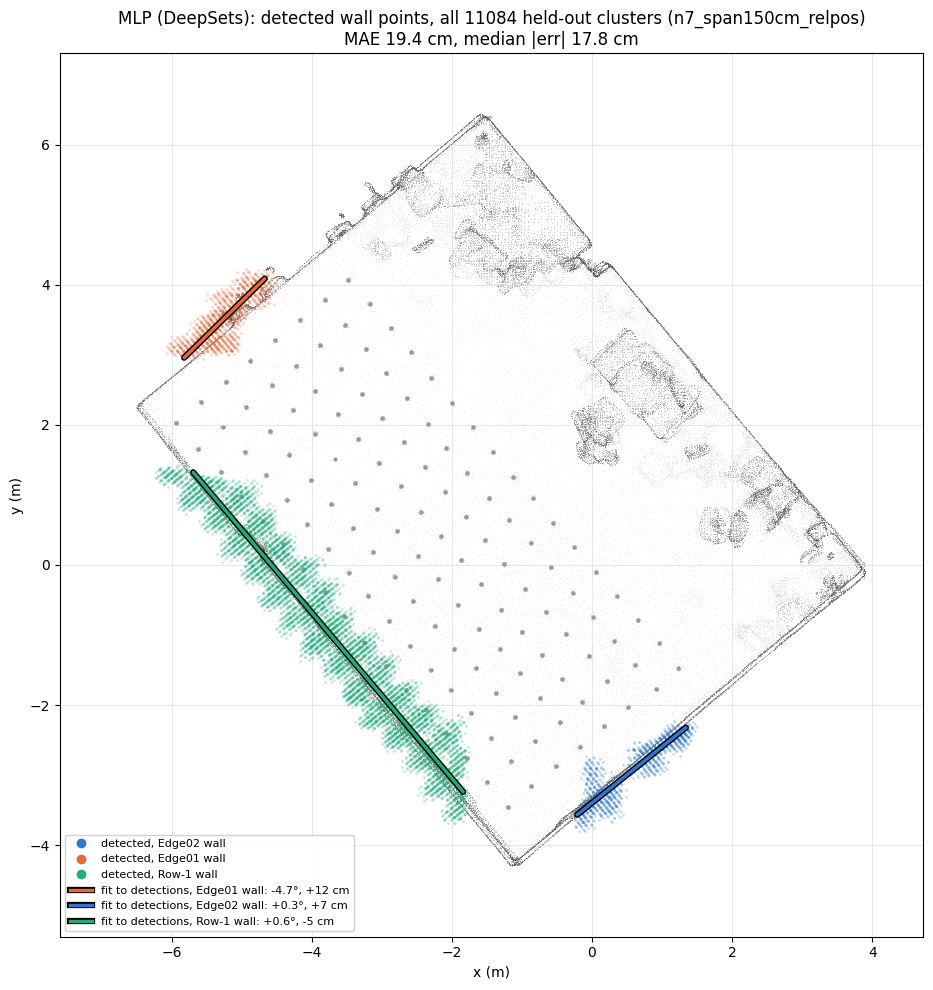

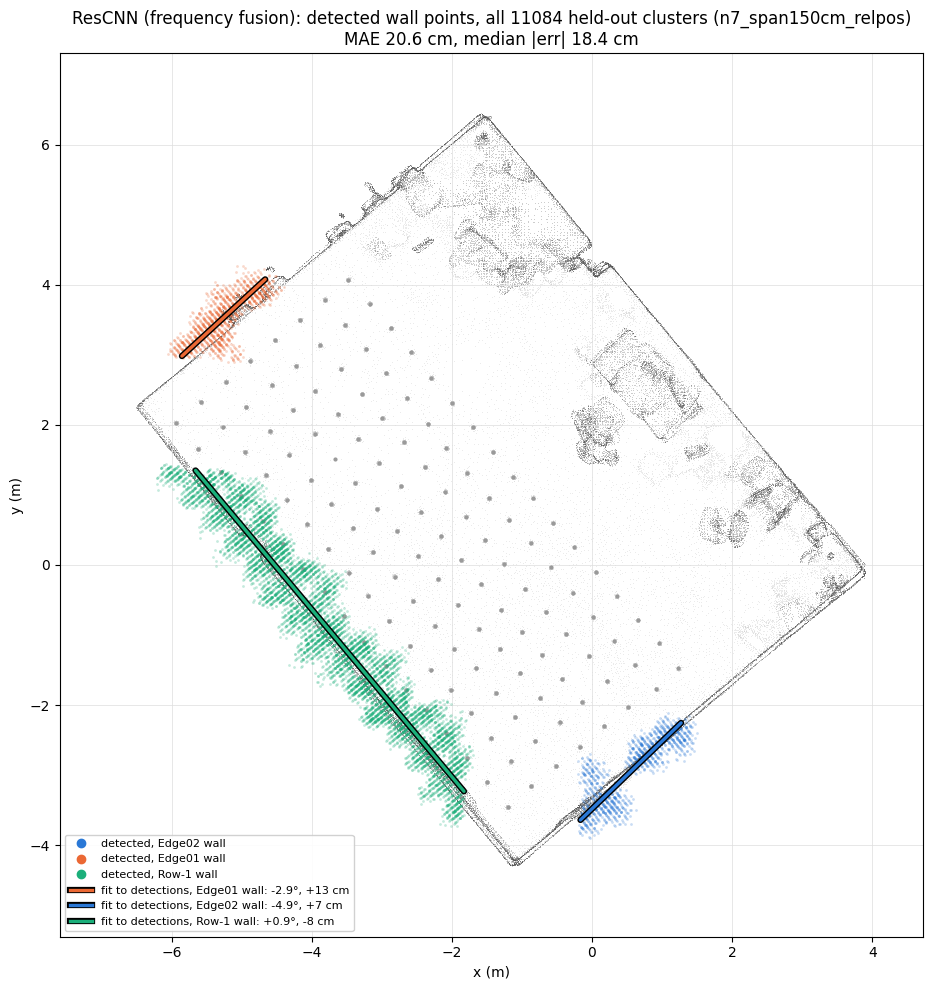

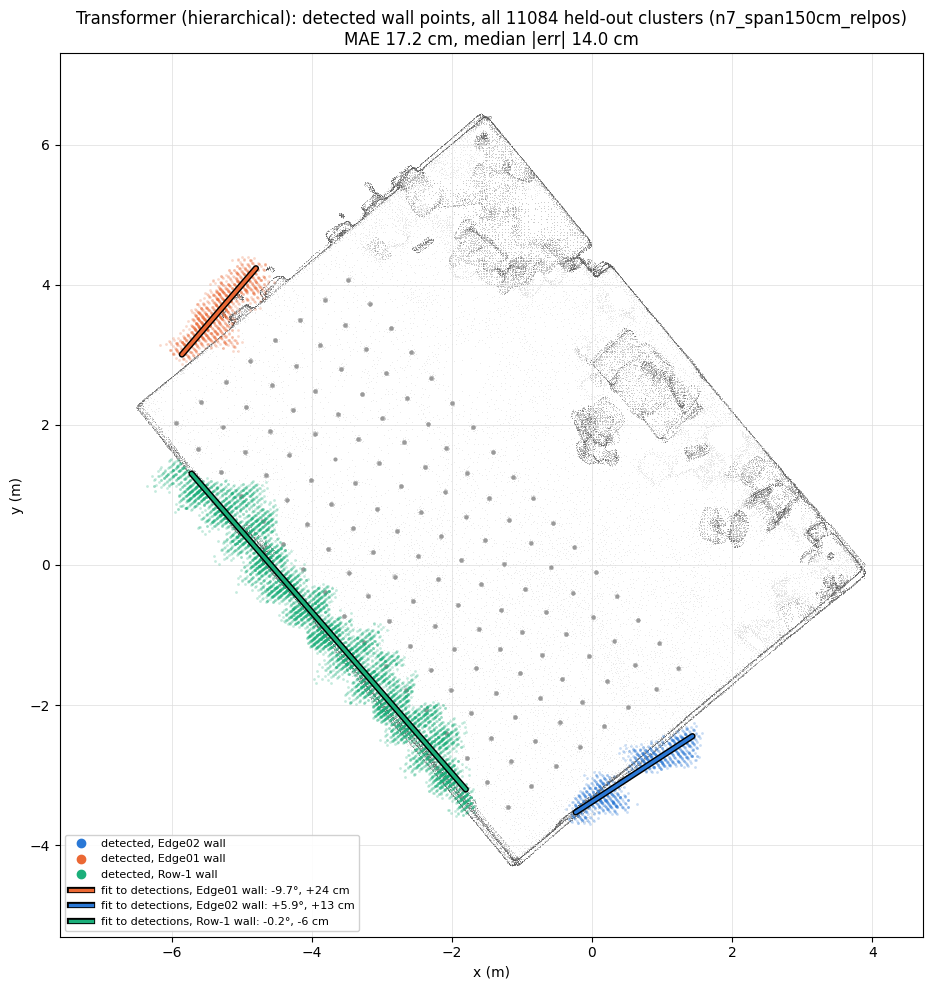

In [29]:
for m in models:
    d = det[m]
    fig, ax = plt.subplots(figsize=(10, 10))
    draw_room(ax)
    fits = []
    for w, g in d.groupby("wall"):
        ax.scatter(g.det_x, g.det_y, s=4, alpha=0.25, color=WALL_COLORS[w], linewidths=0, zorder=4, rasterized=True)
        ends, angle, offset = fit_detected_wall(g, w)
        ax.plot(ends[:, 0], ends[:, 1], color=WALL_COLORS[w], lw=2.4, zorder=6, solid_capstyle="round",
                path_effects=[withStroke(linewidth=4.5, foreground="black")])
        fits.append(Line2D([], [], color=WALL_COLORS[w], lw=2.4, path_effects=[withStroke(linewidth=4.5, foreground="black")],
                           label=f"fit to detections, {w}: {angle:+.1f}°, {offset:+.0f} cm"))
    set_room_limits(ax)
    wall_legend(ax, fits, loc="lower left")
    ax.set_title(f"{m}: detected wall points, all {len(d)} held-out clusters ({RUN})\n"
                 f"MAE {d.err_cm.abs().mean():.1f} cm, median |err| {d.err_cm.abs().median():.1f} cm")
    fig.tight_layout()
    plt.show()

## Per experiment (one figure per model)

One panel per held-out experiment. Blue dots are that experiment's tags (labelled with the floor label), small grey
dots are the centroids of its clusters, and the coloured dots are the detected wall points. The dashed line is the
detected wall: the `find_walls()` wall shifted by the median signed error. Titles give the fold MAE from `folds_<RUN>.csv`.

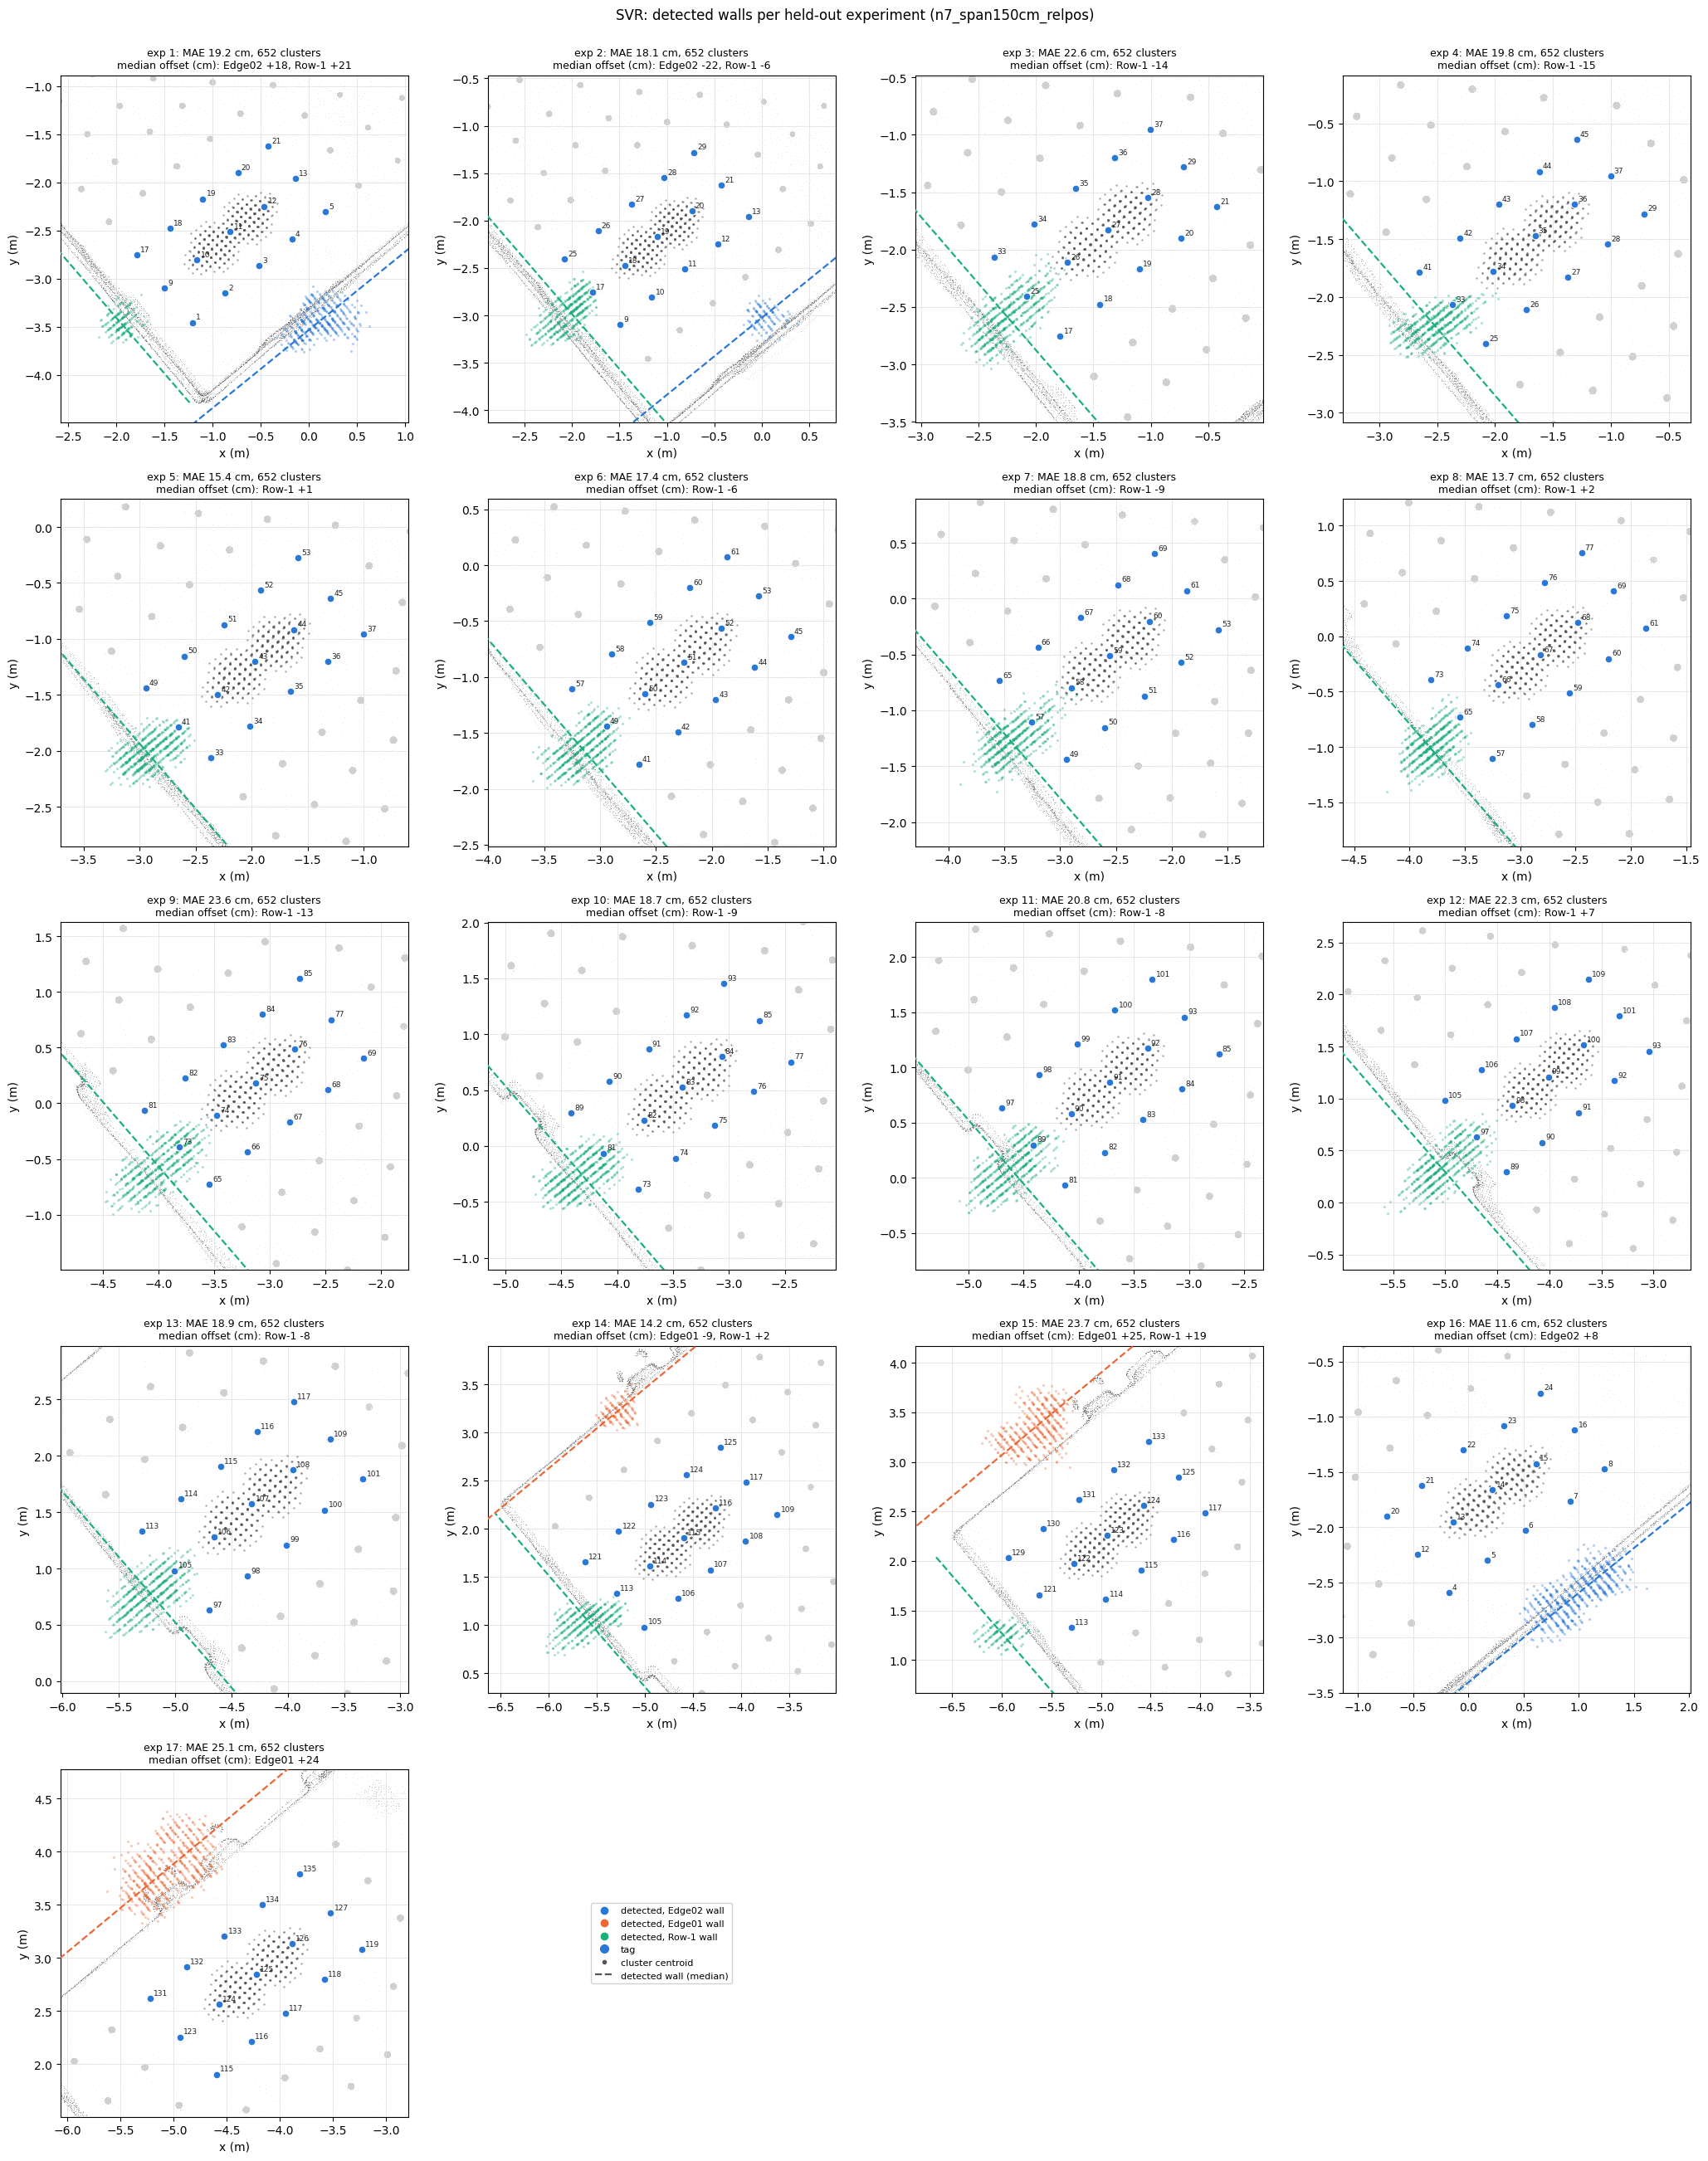

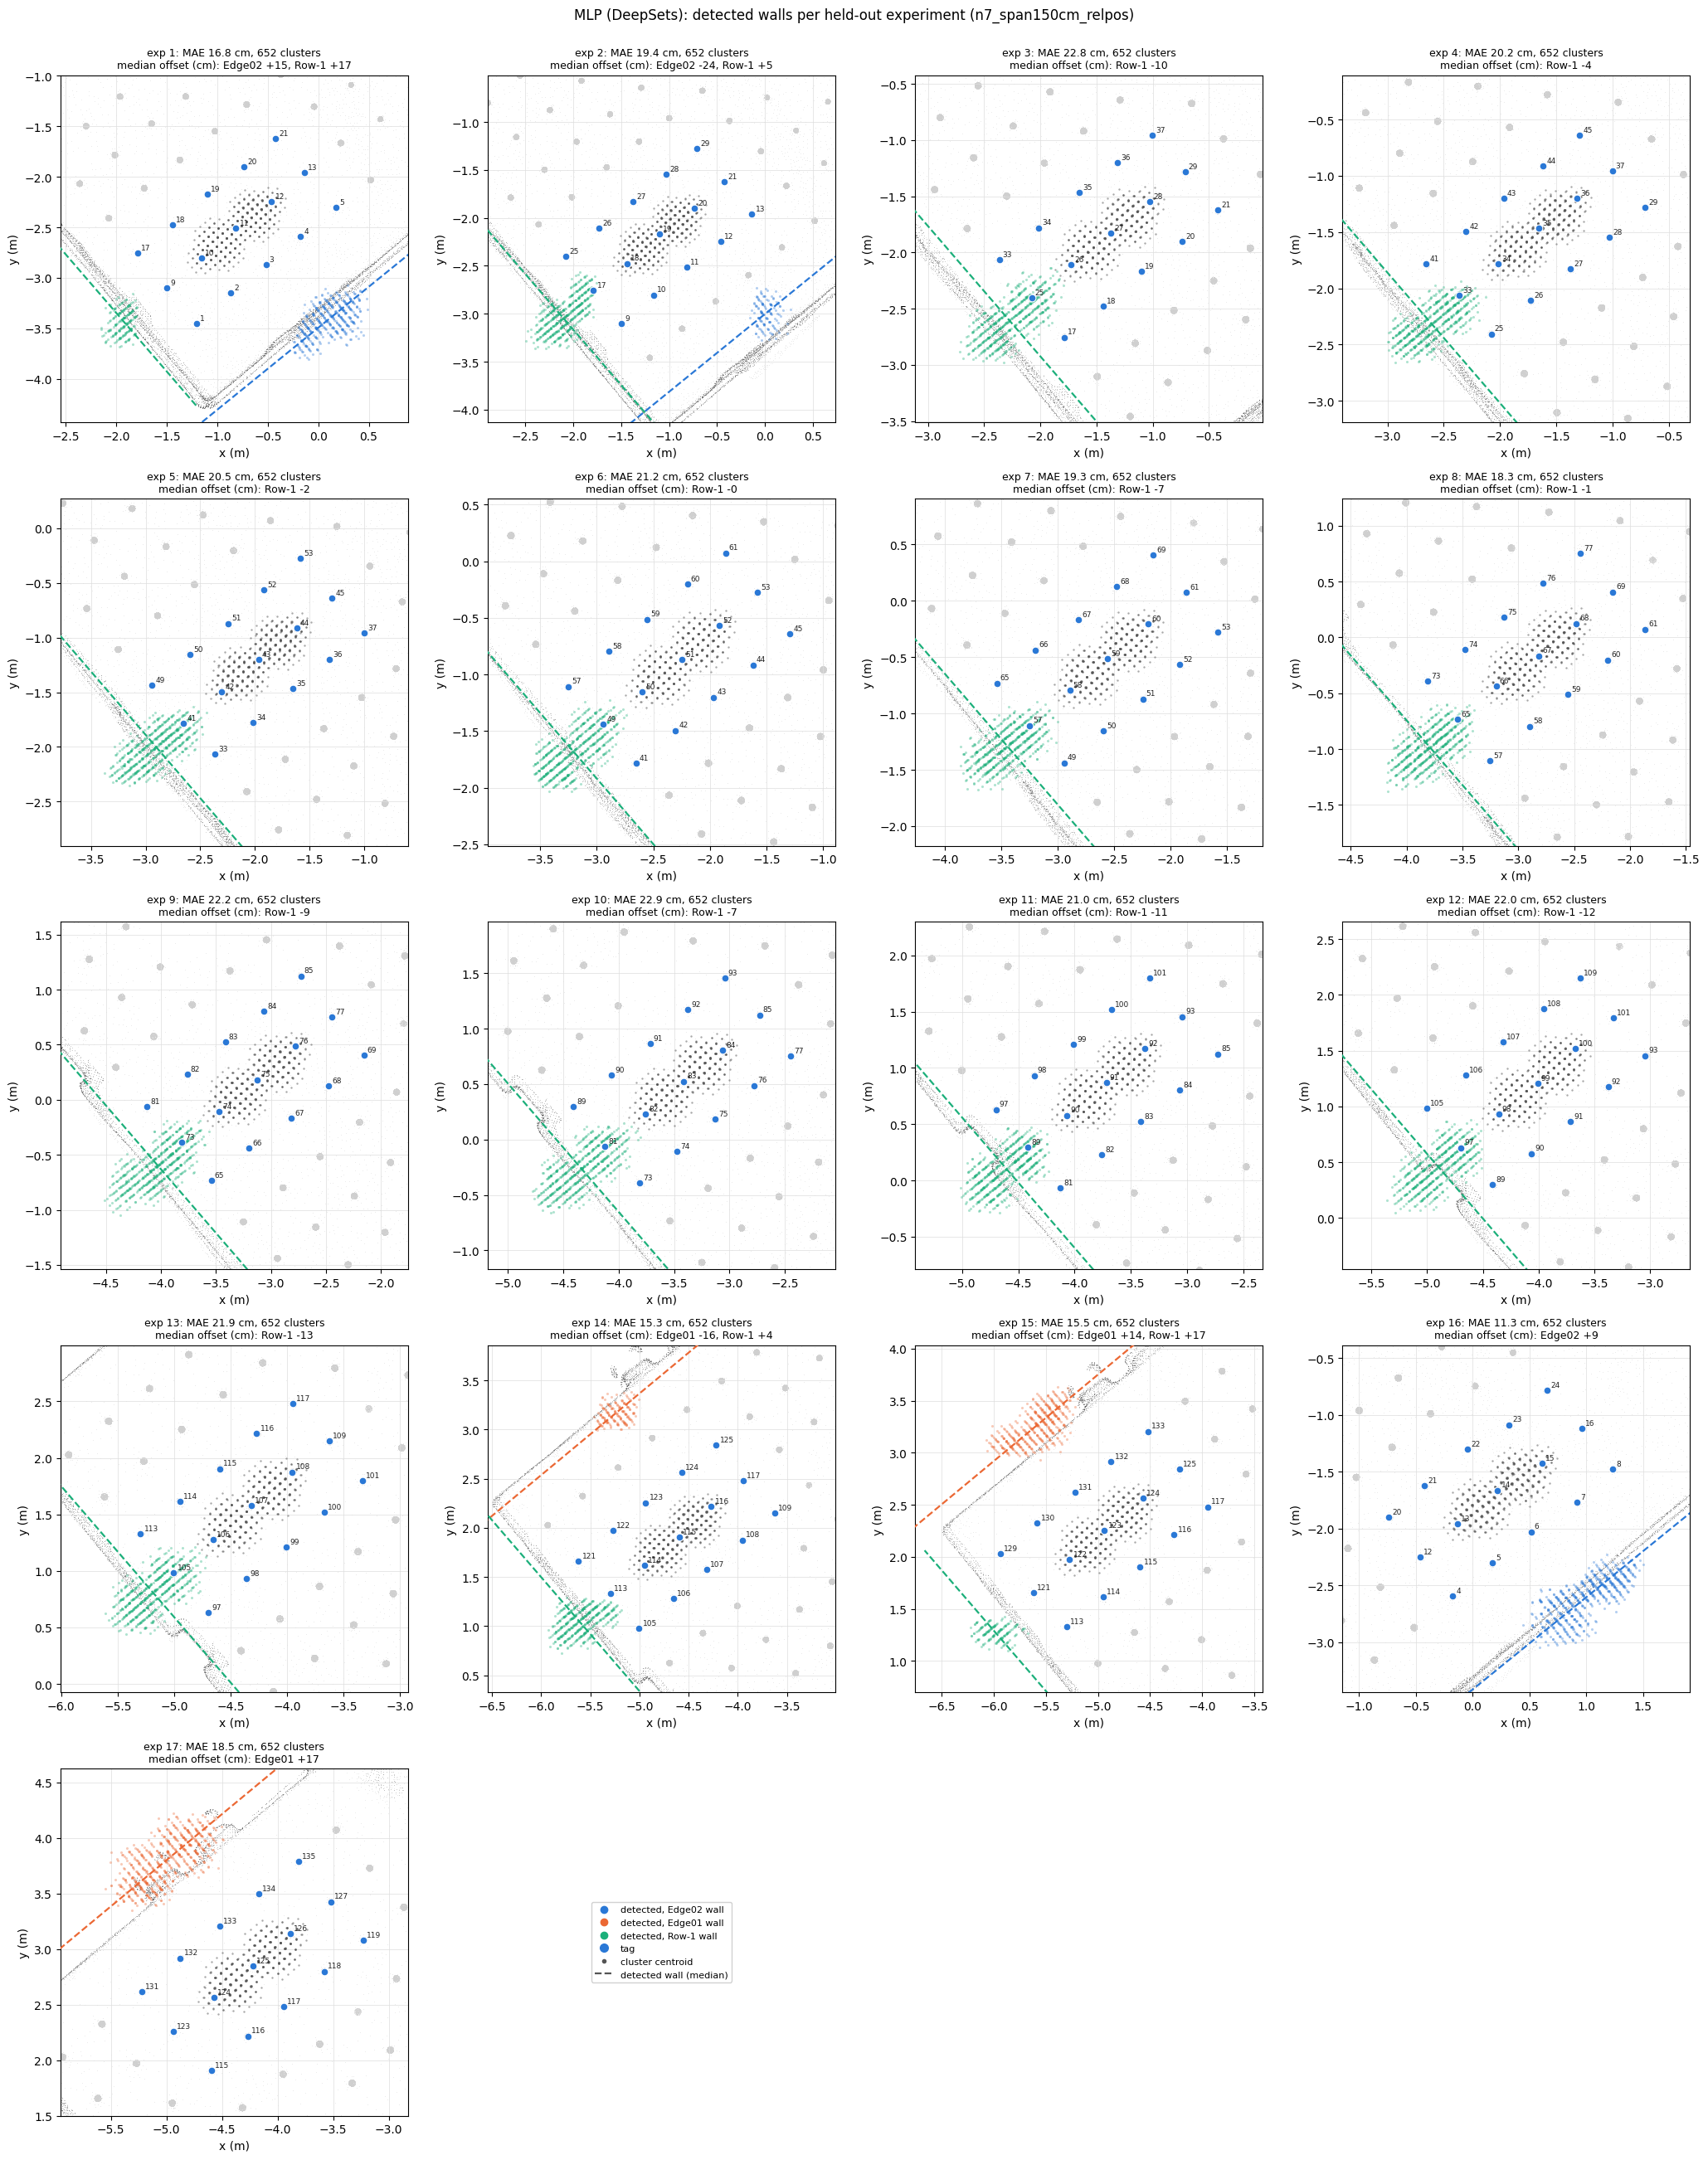

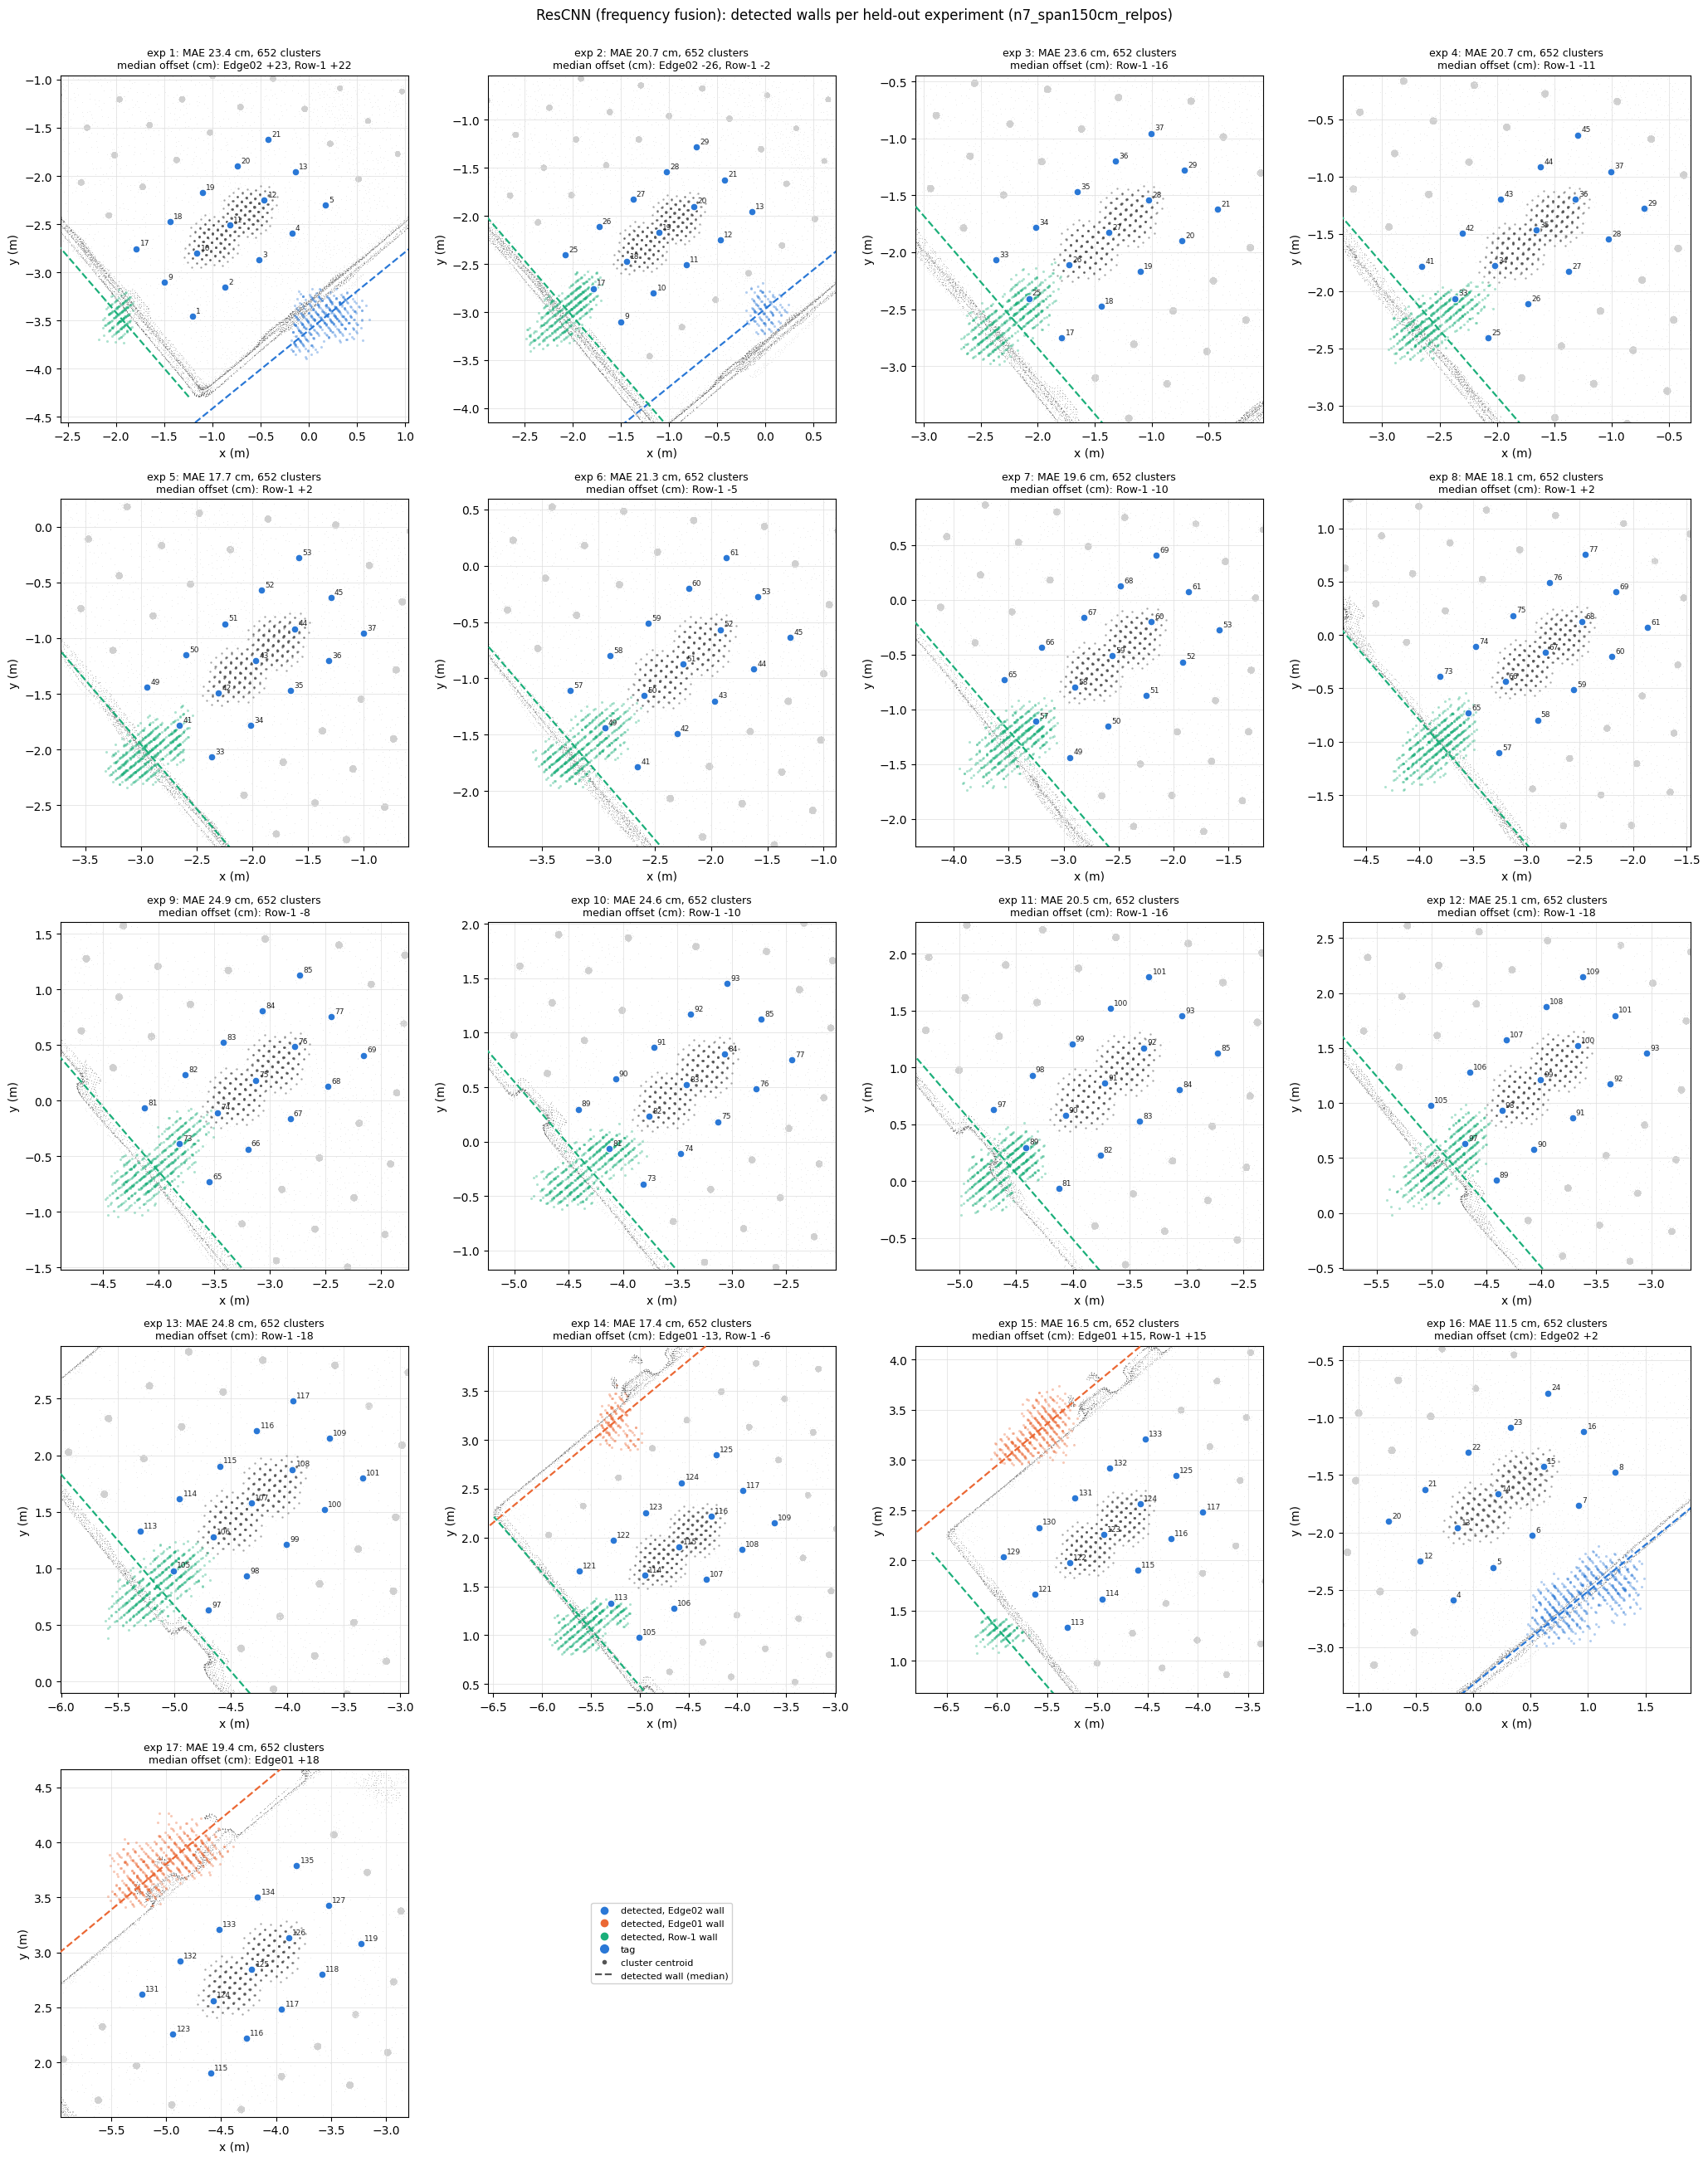

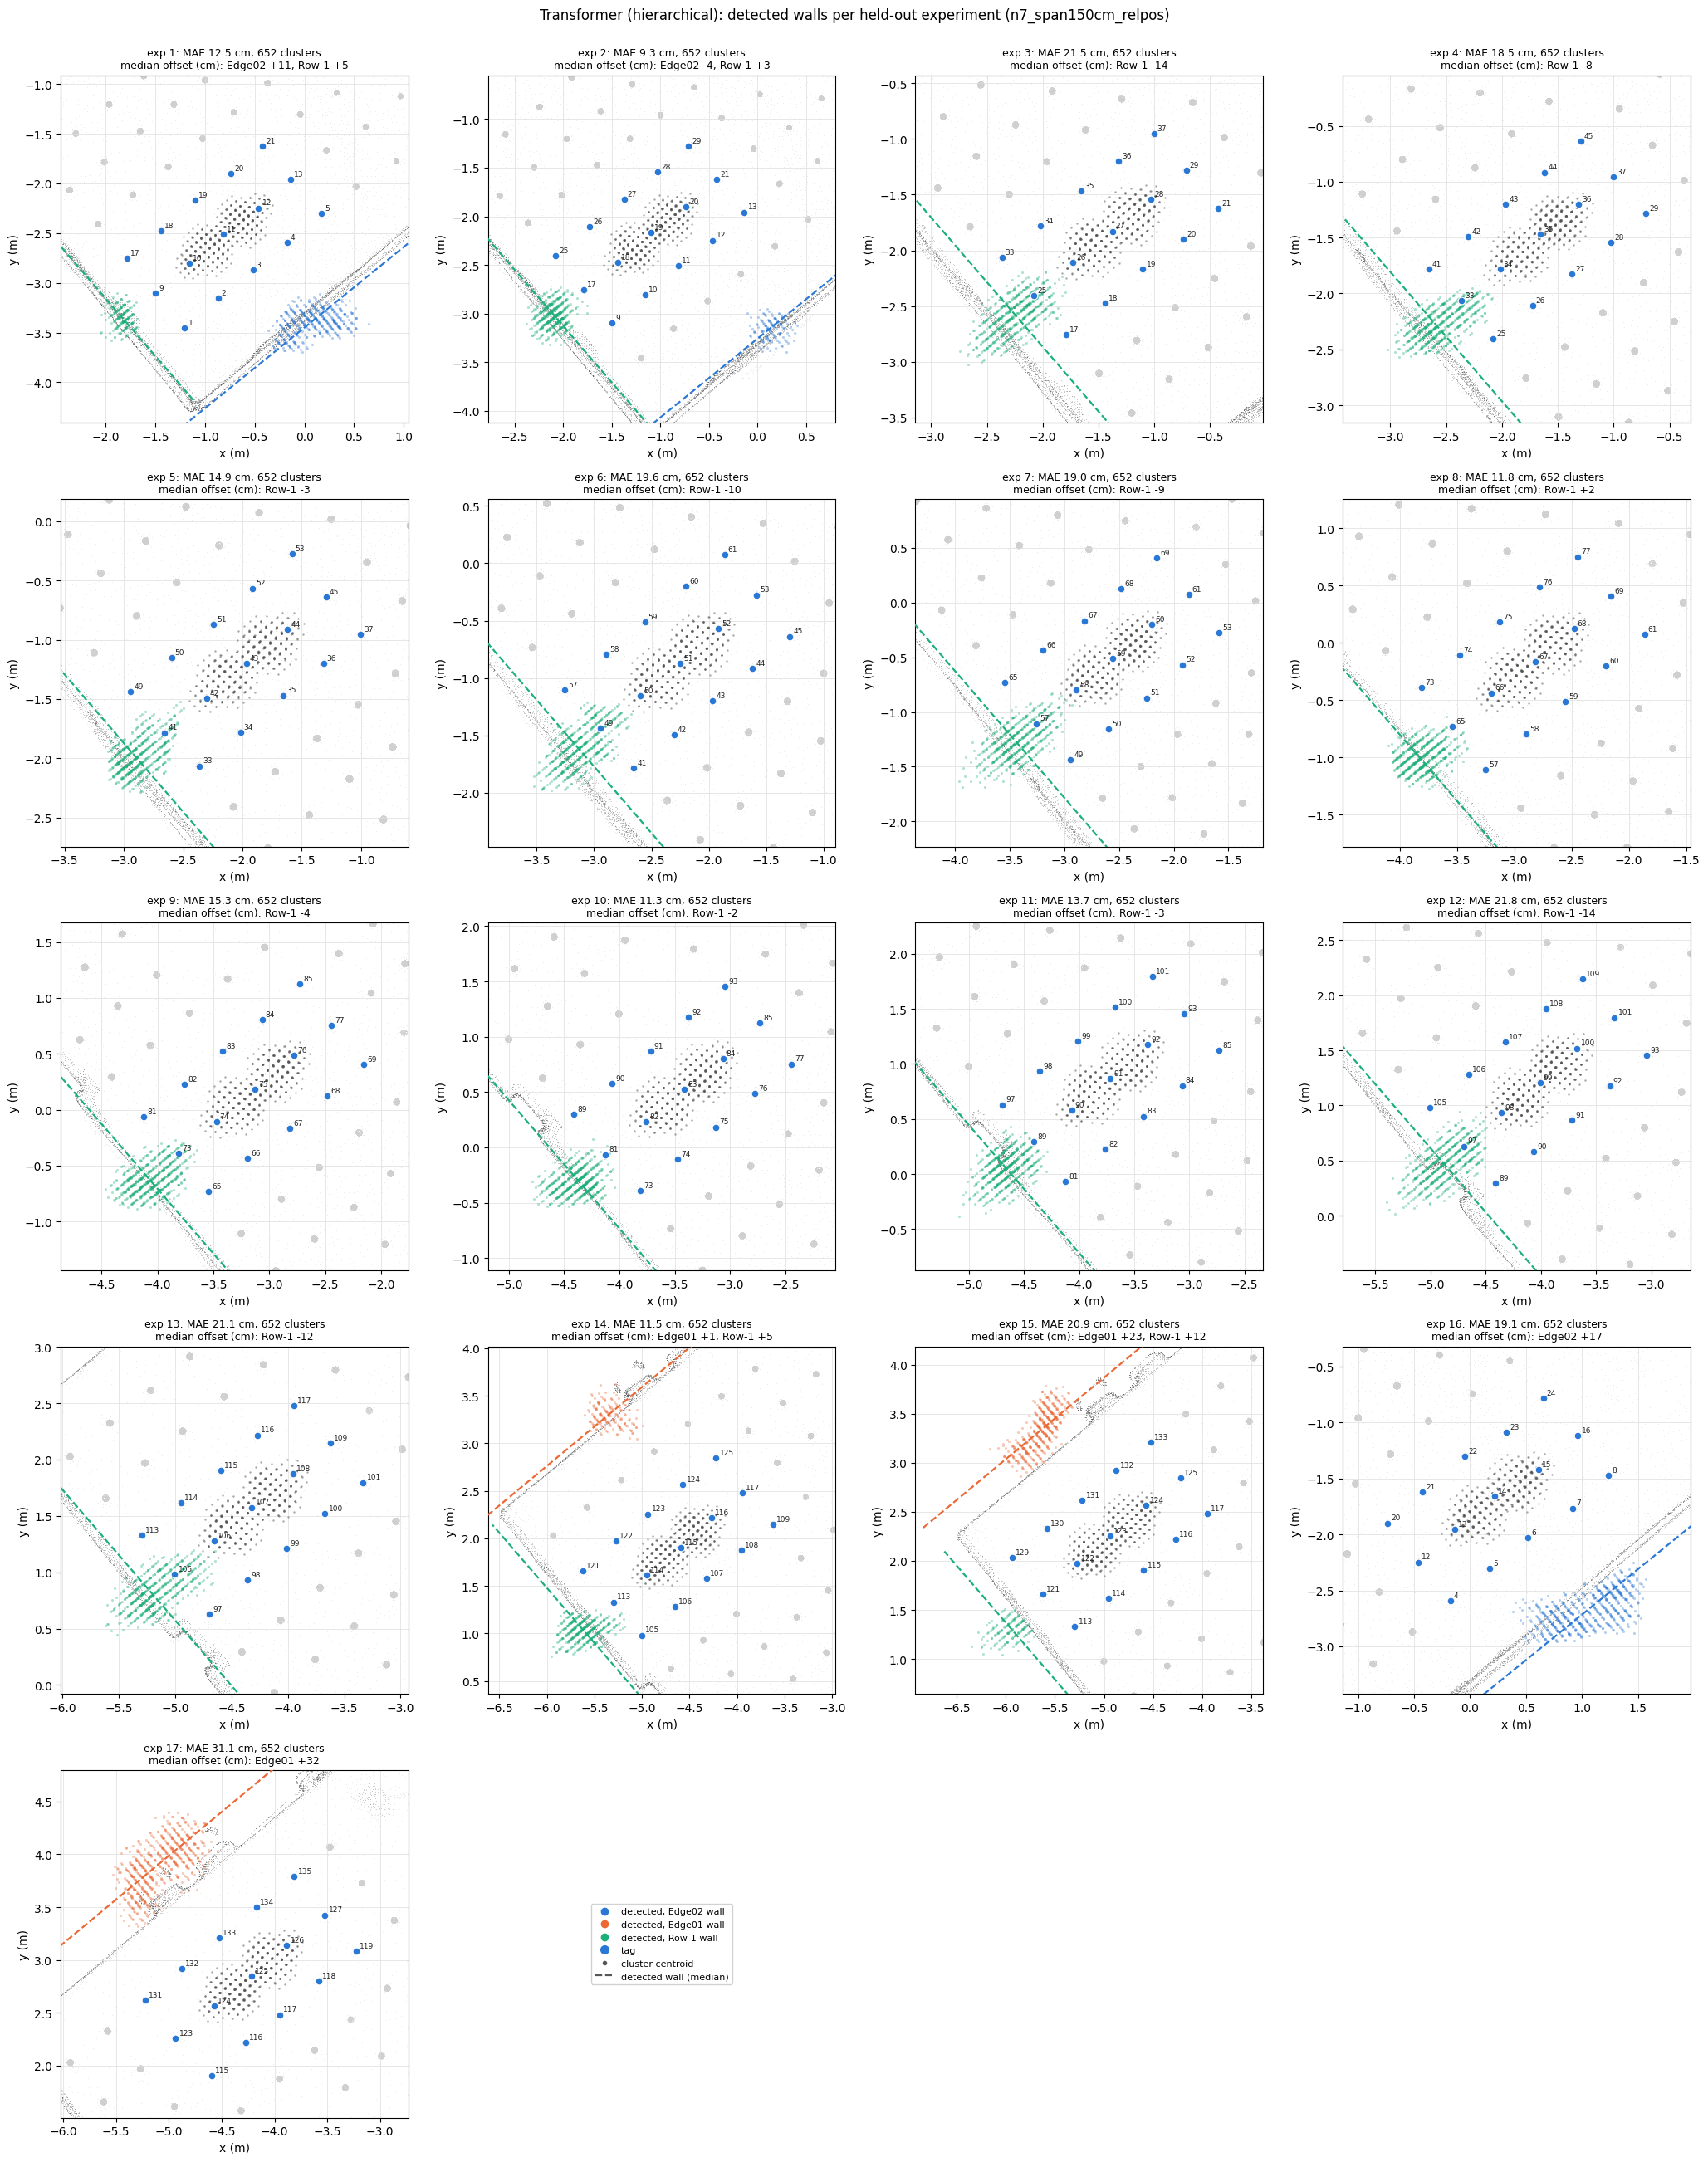

In [30]:
def plot_experiment(ax, exp, model, zoom=True, n_rays=0):
    d = det[model][det[model].exp == exp]
    draw_room(ax, grid=not zoom)
    near = list(d.wall.unique())
    for w, g in d.groupby("wall"):
        ax.scatter(g.det_x, g.det_y, s=5, alpha=0.35, color=WALL_COLORS[w], linewidths=0, zorder=6, rasterized=True)
        s = wall_segment(w, offset_cm=g.err_cm.median())
        ax.plot(s[:, 0], s[:, 1], color=WALL_COLORS[w], lw=1.6, ls="--", zorder=6)
    if n_rays:
        rows = d.sample(min(n_rays, len(d)), random_state=0)
        for r in rows.itertuples():
            ax.plot([r.centroid_x, r.foot_x], [r.centroid_y, r.foot_y], color="#9a9a9a", lw=0.7, zorder=5)
            ax.plot([r.foot_x, r.det_x], [r.foot_y, r.det_y], color=WALL_COLORS[r.wall], lw=1.4, zorder=6)
    ax.scatter(d.centroid_x, d.centroid_y, s=3, color="#555555", alpha=0.5, linewidths=0, zorder=6)
    draw_tags(ax, exp)
    if zoom:
        pts = np.concatenate([d[["det_x", "det_y"]].to_numpy(), d[["foot_x", "foot_y"]].to_numpy(),
                              markers.loc[positions[str(exp)].label, ["x", "y"]].to_numpy()])
        lo, hi = pts.min(0) - 0.4, pts.max(0) + 0.4
        half = (hi - lo).max() / 2
        mid = (lo + hi) / 2
        ax.set_xlim(mid[0] - half, mid[0] + half)
        ax.set_ylim(mid[1] - half, mid[1] + half)
    else:
        set_room_limits(ax)
    mae = folds.loc[exp, f"{model} MAE"] if f"{model} MAE" in folds else d.err_cm.abs().mean()
    offs = ", ".join(f"{w.replace(' wall', '')} {g.err_cm.median():+.0f}" for w, g in d.groupby("wall"))
    ax.set_title(f"exp {exp}: MAE {mae:.1f} cm, {len(d)} clusters\nmedian offset (cm): {offs}", fontsize=9)


exps = sorted(pred.exp.unique())
n_cols = 4
n_rows = int(np.ceil(len(exps) / n_cols))
extra = [Line2D([], [], marker="o", ls="", color="#2a78d6", markersize=7, label="tag"),
         Line2D([], [], marker="o", ls="", color="#555555", markersize=3, label="cluster centroid"),
         Line2D([], [], color="#555555", ls="--", lw=1.6, label="detected wall (median)")]
for m in models:
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 5.2 * n_rows), squeeze=False)
    for ax, exp in zip(axes.flat, exps):
        plot_experiment(ax, exp, m)
    for ax in axes.flat[len(exps):]:
        ax.axis("off")
    spare = len(exps) < axes.size                       # put the legend in an empty slot if there is one
    wall_legend(axes.flat[len(exps)] if spare else axes.flat[0], extra, loc="center" if spare else "lower left")
    fig.suptitle(f"{m}: detected walls per held-out experiment ({RUN})", y=1.0)
    fig.tight_layout()
    plt.show()

## One experiment in detail (`EXP`, one figure per model)

Left: zoomed in, with 40 random clusters drawn as rays. The grey part runs from the centroid to the true wall foot
and the coloured part from the foot to the detected point, so the coloured segment is the error. Right: the same
experiment in the whole room.

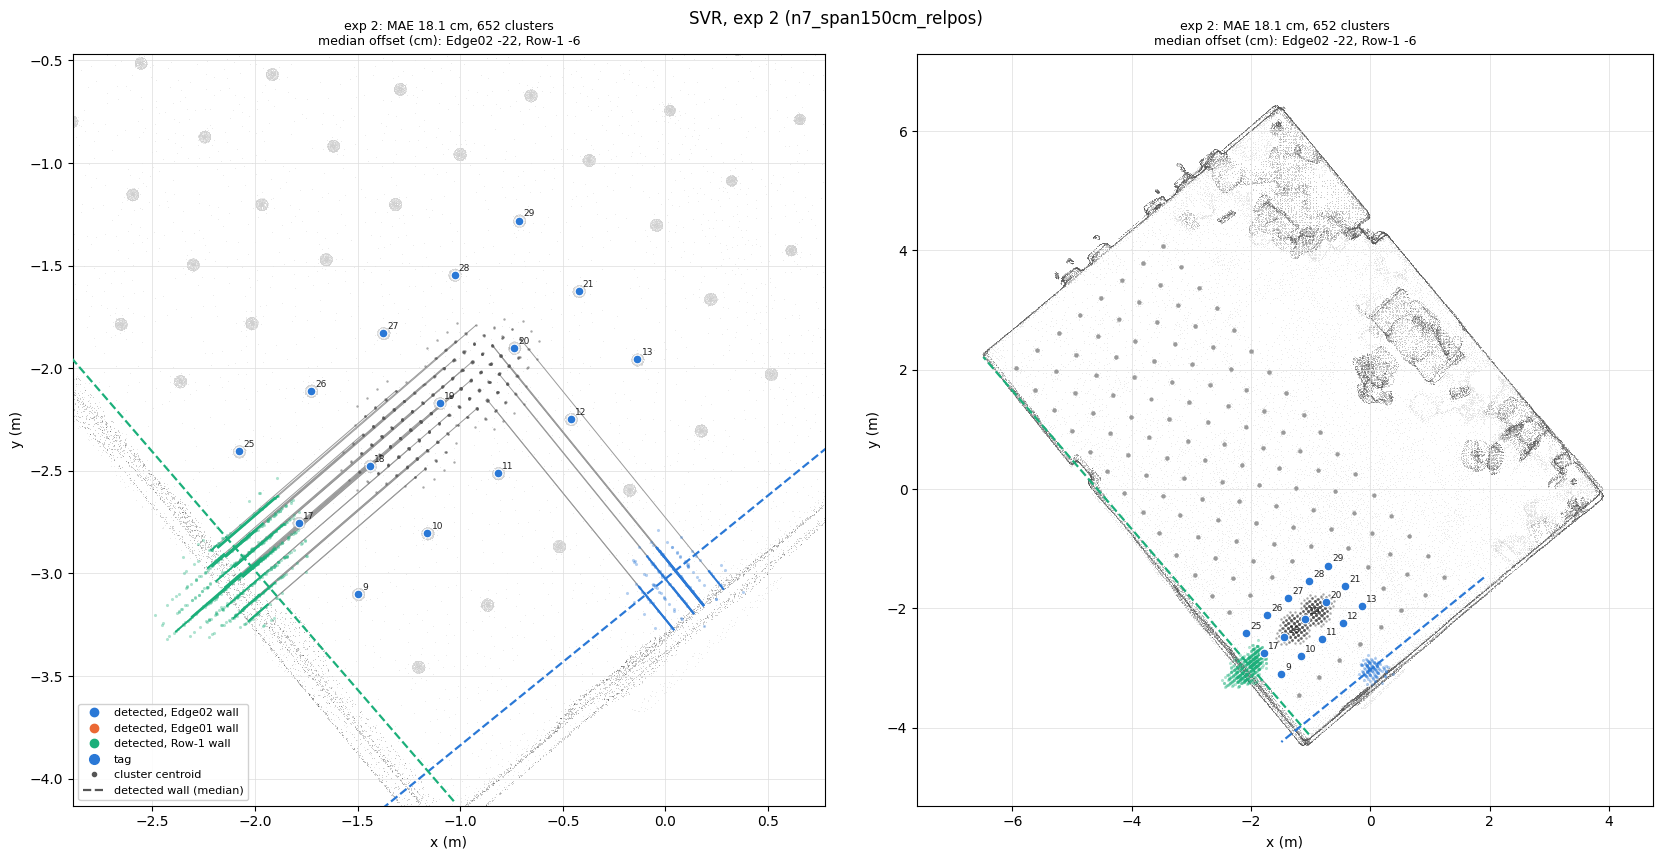

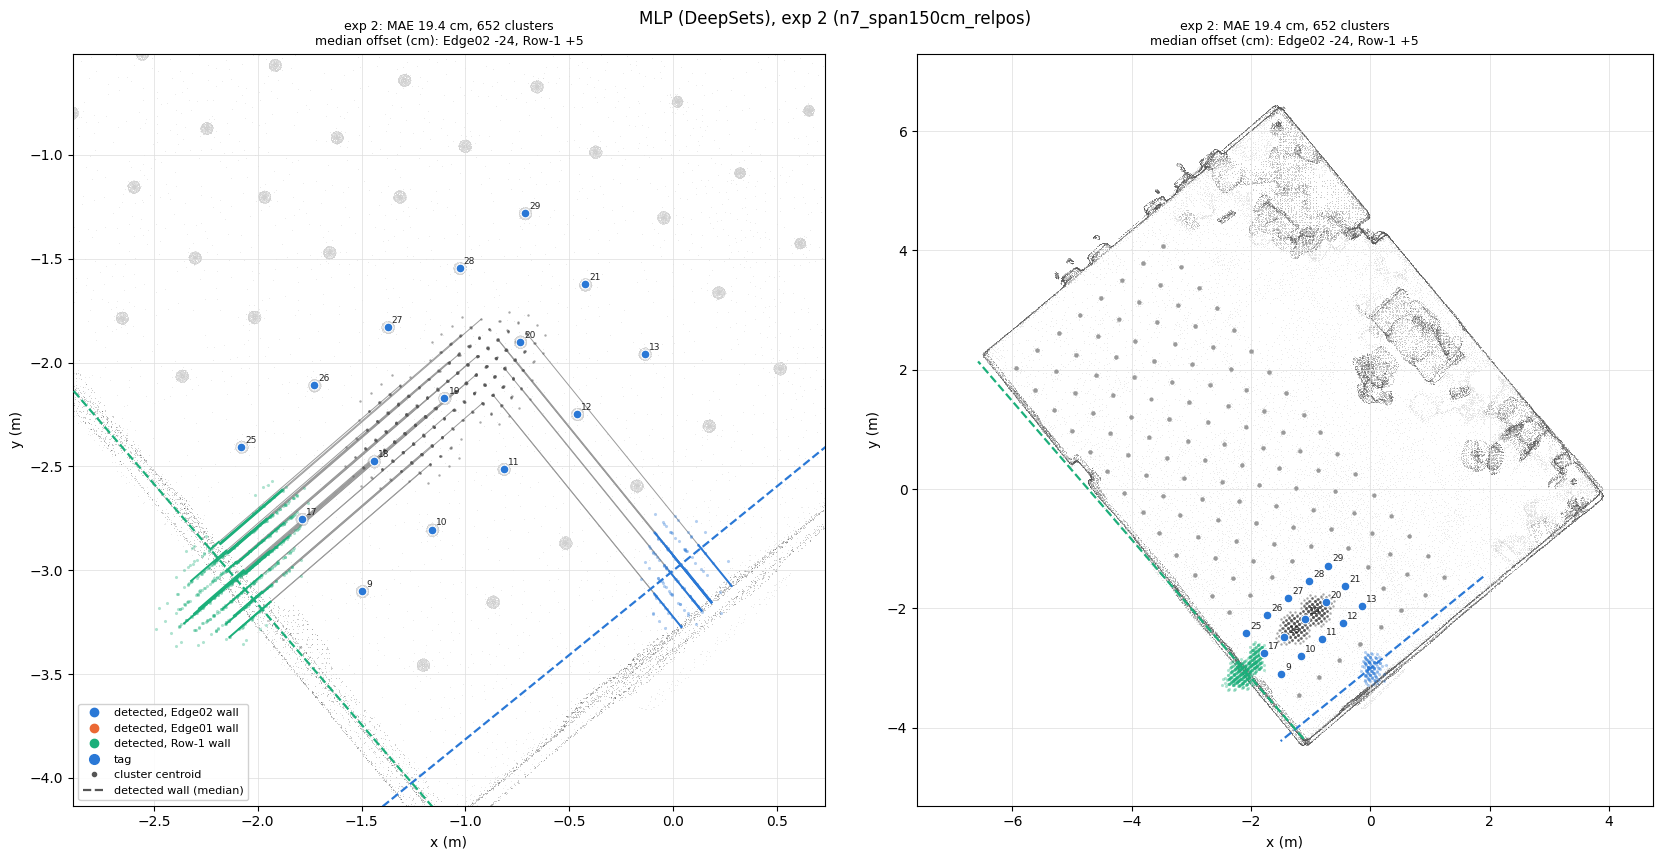

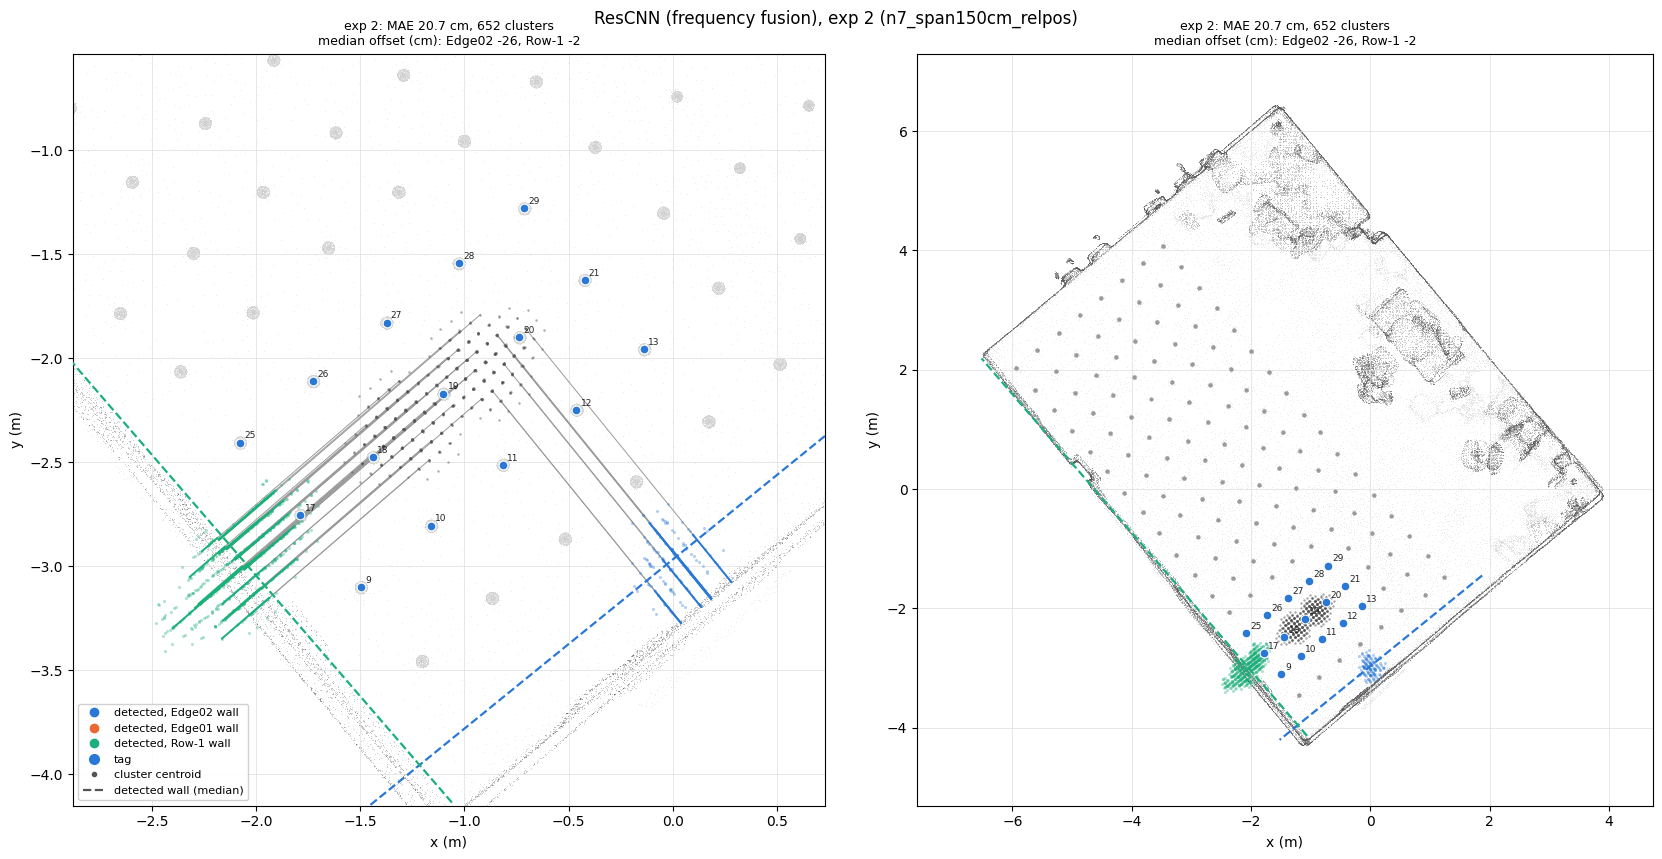

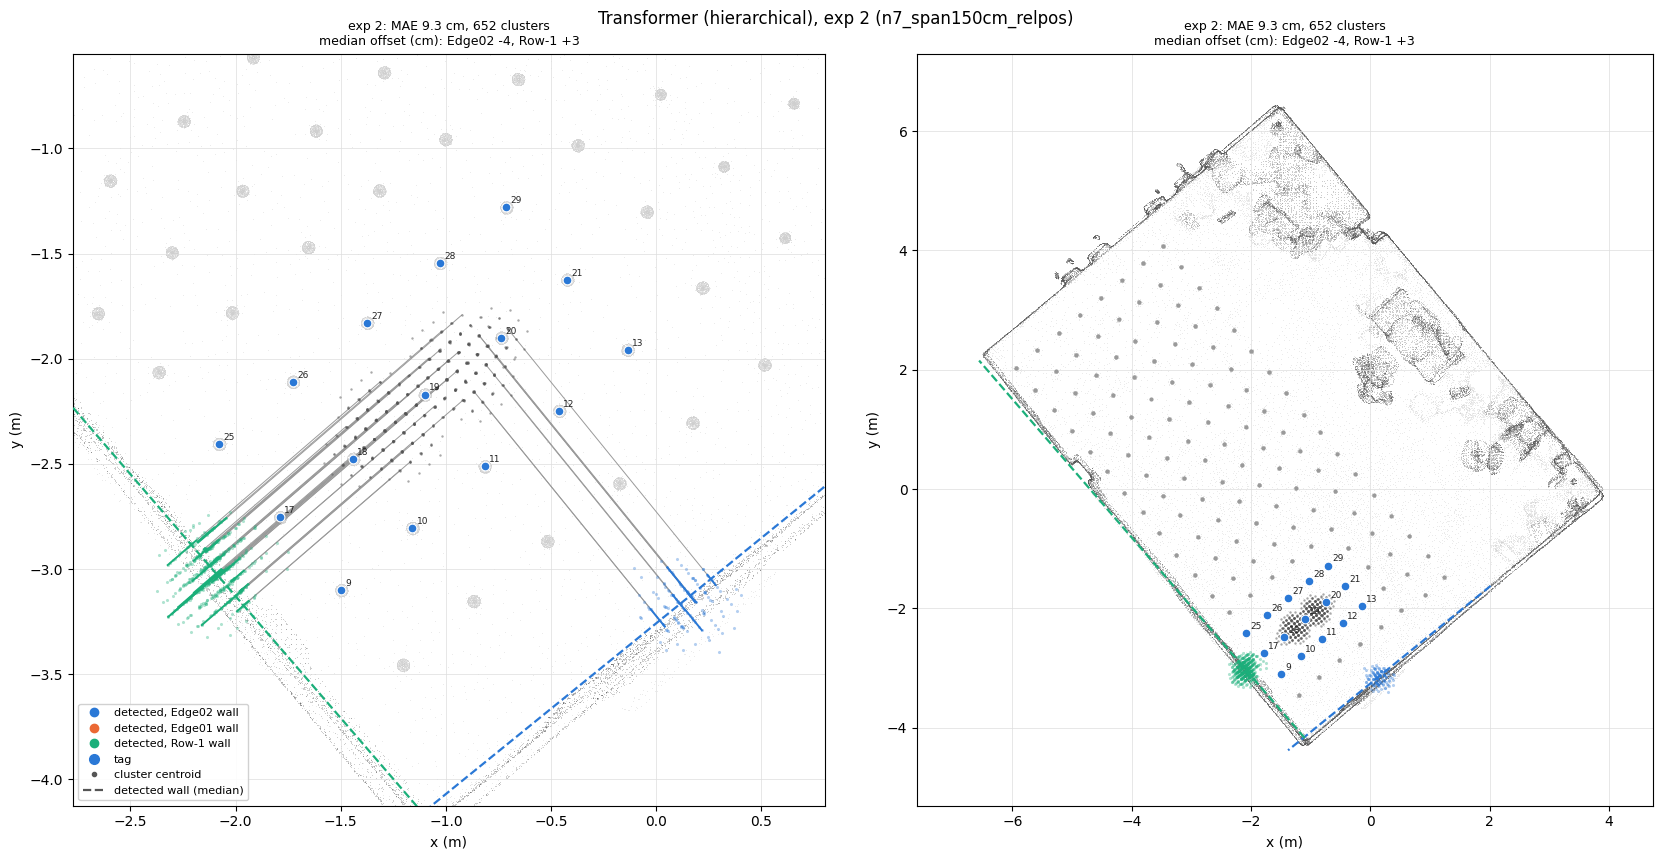

In [31]:
for m in models:
    fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))
    plot_experiment(axes[0], EXP, m, n_rays=40)
    plot_experiment(axes[1], EXP, m, zoom=False)
    wall_legend(axes[0], extra, loc="lower left")
    fig.suptitle(f"{m}, exp {EXP} ({RUN})")
    fig.tight_layout()
    plt.show()

## Signed error per wall (one figure per model)

Distribution of prediction minus truth for each wall. Positive means the detected wall is behind the real one.
This is the same quantity as the dashed offsets above.

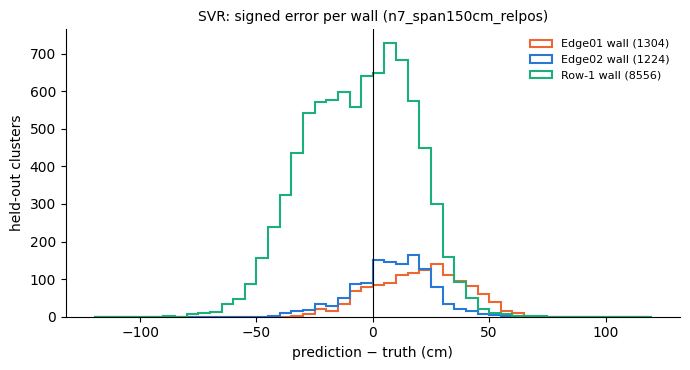

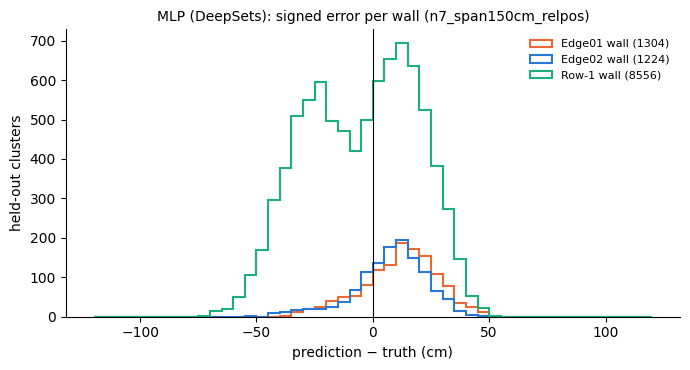

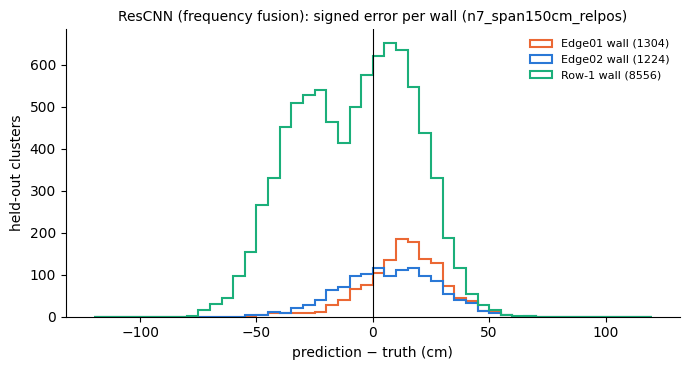

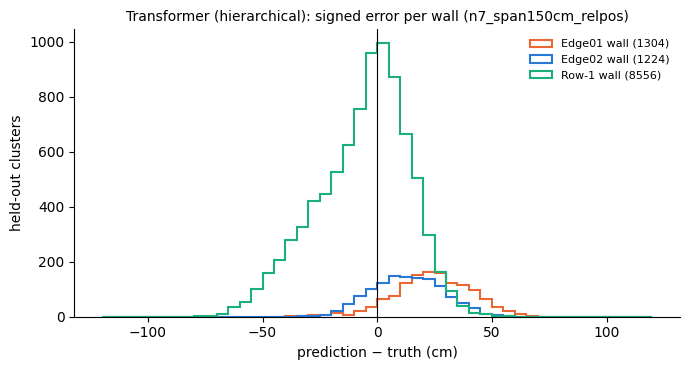

median signed error (cm) per experiment and wall:
                  SVR  MLP (DeepSets)  ResCNN (frequency fusion)  Transformer (hierarchical)
exp wall                                                                                    
1   Edge02 wall  17.7            14.7                       23.1                        11.2
    Row-1 wall   21.1            17.5                       21.9                         4.9
2   Edge02 wall -21.7           -23.5                      -26.2                        -3.7
    Row-1 wall   -6.1             5.4                       -2.3                         3.1
3   Row-1 wall  -13.5           -10.2                      -15.7                       -14.2
4   Row-1 wall  -15.1            -4.0                      -10.6                        -7.6
5   Row-1 wall    0.9            -2.1                        2.0                        -3.3
6   Row-1 wall   -6.4            -0.2                       -4.6                        -9.8
7   Row-1 wall   -8.

In [32]:
bins = np.arange(-120, 121, 5)
for m in models:
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for w, g in det[m].groupby("wall"):
        ax.hist(g.err_cm, bins=bins, histtype="step", lw=1.5, color=WALL_COLORS[w], label=f"{w} ({len(g)})")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{m}: signed error per wall ({RUN})", fontsize=10)
    ax.set_xlabel("prediction − truth (cm)")
    ax.set_ylabel("held-out clusters")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    plt.show()

table = pd.concat({m: det[m].groupby(["exp", "wall"]).err_cm.median() for m in models}, axis=1).round(1)
print("median signed error (cm) per experiment and wall:")
print(table.to_string())